<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 4 · Regression</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">School maths. Python or R for the notebooks.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A residual is what the data did minus what the model said. Anything you can see in them is something the model missed. Four plots cover most of it. A curve against fitted values means missing shape or a missing variable. Spread that grows with the fitted value means proportional errors: model the log. Neighbouring weeks' residuals that move together mean ignored persistence: errors come in runs and intervals are too narrow. Q–Q ends that bend away mean heavy tails or bad records. On a synthetic weekly berry harvest, a straight-line model leaves a lag-1 residual correlation of 0.91, mostly missing shape; the right shape on the log scale leaves 0.36, the real weather. In a forecast, a new block on one farm shows up as that farm's mean log residual jumping from 0.02 to 0.18.

Read the residuals in order, shape first.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from scipy.signal import lfilter

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
c1, c2, c3, c4 = fallcolor.palette.discrete("default")
rng = np.random.default_rng(2026)

[Least squares](../least-squares.qmd) makes the residuals small; this module reads what is left. Anscombe and Tukey argued that examining residuals, by plots and by numbers, is how you judge whether a fitted analysis was appropriate[^1]. The **residual** for row $i$ is

$$r_i = y_i - \hat{y}_i$$

where $y_i$ is the observed value and $\hat{y}_i$ the fitted value, in the units of the target (t/week, or natural-log units once the target is logged). A log residual of $0.10$ means the actual was $e^{0.10} = 1.105$ times the fit.

The data are a toy harvest where we know the truth, so each diagnosis can be checked. They are synthetic, from a fixed seed: three farms, two varieties, three 26-week seasons, with persistent weather, heavy-tailed one-off weeks, a new block on farm C from week 12 of season 3, and one load entered twice.

::: {.callout-note collapse="true"}
## How the toy harvest is generated

$$V = P_f\, m_s\, b \exp\!\left(-\tfrac12 \left(\tfrac{w - \mu_v}{6}\right)^2 + \varepsilon_w + \delta_w\right)$$

where $V$ is volume (t/week), $P_f$ the farm's peak (40, 25 and 60 t/week for farms A, B and C), $m_s$ a season multiplier (1.00, 1.10, 1.05), $w$ the week of the season, $\mu_v$ the peak week (11 early variety, 15 late), $\varepsilon_w$ persistent weather noise (autoregressive, lag-1 correlation $0.6$, standard deviation $0.12$), and $\delta_w$ one-off shocks ($0.06$ times a Student t with 3 degrees of freedom). The block factor $b$ is 1, except 1.3 for farm C from week 12 of season 3. Farm B's late variety has its week-14 load in season 2 entered twice.
:::

In [2]:
# Toy harvest with a known truth (synthetic); the equation is in the note above.
farms = {"A": 40, "B": 25, "C": 60}       # peak volume, t/week
varieties = {"early": 11, "late": 15}      # week of peak
seasons = {1: 1.00, 2: 1.10, 3: 1.05}      # season-wide yield multiplier
week = np.arange(1, 27)
parts = []
for (f, peak), (v, mu), (s, m) in [(a, b, c) for a in farms.items() for b in varieties.items() for c in seasons.items()]:
    weather = lfilter([1], [1, -0.6], rng.normal(0, 0.12 * 0.8, 26 + 50))[50:]   # persistent, SD 0.12
    shocks = 0.06 * rng.standard_t(3, 26)                                       # one-off weeks, heavy-tailed
    block = np.where((f == "C") & (s == 3) & (week >= 12), 1.3, 1.0)           # new block from week 12 of season 3
    vol = peak * m * block * np.exp(-0.5 * ((week - mu) / 6) ** 2 + weather + shocks)
    parts.append(pd.DataFrame({"farm": f, "variety": v, "season": s, "week": week, "volume": vol}))
df = pd.concat(parts, ignore_index=True)
typo = (df.farm == "B") & (df.variety == "late") & (df.season == 2) & (df.week == 14)
df.loc[typo, "volume"] *= 2                                                     # a load entered twice
keys = ["farm", "variety", "season"]                                            # one series per key
train = df[df.season < 3]
print(f"{len(df)} rows: {df.groupby(keys).ngroups} series of {len(week)} weeks; training on seasons 1-2, {len(train)} rows")

468 rows: 18 series of 26 weeks; training on seasons 1-2, 312 rows


## The model's confession

The flawed model is `volume ~ week + farm + variety`: a straight line in week with farm and variety offsets, in raw tonnes, fitted to seasons 1 and 2. The helper below runs four checks and draws a panel for each. Copy it:

In [3]:
def residual_report(resid, fitted, series, lags=8, plot=True):
    """Four residual checks. Rows must be in time order within each series;
    `series` is a column or list of columns naming the series each row belongs to.
    For flexible models (e.g. gradient boosting) pass out-of-fold or backtest
    predictions: in-sample residuals are too small."""
    r, f = pd.Series(resid), pd.Series(fitted)
    g = r.groupby(series)
    acf = [r.corr(g.shift(k)) for k in range(1, lags + 1)]           # within-series autocorrelation
    n = len(r)
    q = n * (n + 2) * sum(acf[k] ** 2 / (n - k - 1) for k in range(4))   # Ljung-Box, 4 lags, pooled
    fifth, third = pd.qcut(f, 5, labels=False), pd.qcut(f, 3, labels=False)
    sd = r.groupby(third).std()
    z = (r - r.median()) / stats.median_abs_deviation(r, scale="normal")  # robust z-score
    print(f"mean residual by fitted fifth: {r.groupby(fifth).mean().round(2).tolist()}\n"
          f"spread, top/bottom third of fitted: {sd.iloc[-1] / sd.iloc[0]:.2f}\n"
          f"lag-1 autocorrelation: {acf[0]:.2f}; Ljung-Box (4 lags) p = {stats.chi2.sf(q, 4):.1g}\n"
          f"excess kurtosis: {stats.kurtosis(r):.1f}; largest robust z: {z.abs().max():.1f} at row {z.abs().idxmax()}")
    if not plot:
        return
    fig, ax = plt.subplots(2, 2, figsize=(8, 6))
    for a, y, lab in [(ax[0, 0], r, "residual"), (ax[0, 1], r.abs(), "|residual|")]:
        a.scatter(f, y, s=6, color=c2, alpha=0.6)
        a.plot(f.groupby(fifth).mean(), y.groupby(fifth).mean(), "o-", color=c1)   # binned means
        a.set(xlabel="fitted", ylabel=lab)
    ax[0, 0].axhline(0, color="grey", lw=0.8)
    ax[1, 0].bar(range(1, lags + 1), acf, color=c3)
    ax[1, 0].axhspan(-2 / np.sqrt(len(r)), 2 / np.sqrt(len(r)), color="grey", alpha=0.2)
    ax[1, 0].set(xlabel="lag (weeks)", ylabel="autocorrelation")
    (q, rs), _ = stats.probplot(z)
    ax[1, 1].scatter(q, rs, s=6, color=c2)
    ax[1, 1].plot(q, q, color=c1)
    ax[1, 1].set(xlabel="normal quantile", ylabel="robust z of residual")
    fig.tight_layout()
    plt.show()

Its four printed lines match the panels: fifth means (top left), spread ratio (top right), autocorrelation and Ljung–Box (bottom left), kurtosis and largest robust z (bottom right). For your data, pass your residuals, fitted values and series columns, with rows in time order within each series.

The checks apply to any model, gradient boosting included, if the residuals come from out-of-fold or backtest predictions: a flexible model's in-sample residuals are too small because it has partly fitted the noise ([Cross-validation](../cross-validation/cross_validation.ipynb), [Backtest design](../backtest-design/backtest_design.ipynb)).

mean residual by fitted fifth: [2.02, -5.79, 7.2, -7.67, 4.17]
spread, top/bottom third of fitted: 2.19
lag-1 autocorrelation: 0.91; Ljung-Box (4 lags) p = 8e-148
excess kurtosis: -0.4; largest robust z: 2.6 at row 352


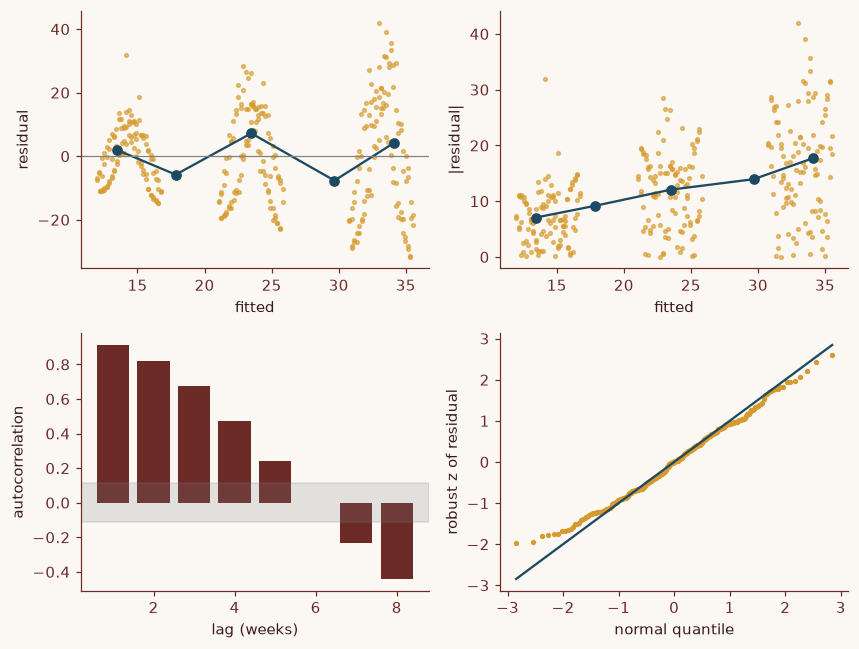

In [4]:
m0 = smf.ols("volume ~ week + farm + variety", train).fit()
residual_report(m0.resid, m0.fittedvalues, [train.farm, train.variety, train.season])

<strong>Figure 1 | What a straight line confesses.</strong> Top: residuals and their size against fitted values; the line joins the means of each fifth. Bottom left: within-series autocorrelation; independent residuals would mostly stay inside the grey band, $\pm 2/\sqrt{n}$. Bottom right: Q–Q plot of robust z-scores, built from the median and median absolute deviation so one wild value barely moves the scale.

Read the panels in order, because each contaminates the ones after it.

1. **Pattern.** The fifth means swing from $+2.02$ to $-5.79$, $+7.20$, $-7.67$ and $+4.17$ t/week, and each farm's cloud traces arches: a straight line cannot follow a season that rises and falls.
2. **Spread.** The top third of fitted values has $2.19$ times the residual standard deviation of the bottom third.
3. **Autocorrelation.** Lag 1 is $0.91$ (Ljung–Box $p = 8 \times 10^{-148}$), mostly the missed curve, wrong by similar amounts in neighbouring weeks.
4. **Tails.** The Q–Q plot looks light-tailed (excess kurtosis $-0.4$, largest robust z $2.6$) and misses the record entered twice; the misfit swamps both.

| What you see | What the model is confessing | What to change |
|---|---|---|
| Arches against fitted | Wrong shape or missing variable | Add the term or a spline |
| Spread grows with the fitted value | Errors proportional to the level | Model the log, or score relative error |
| Neighbouring residuals alike | Ignored persistence | Add lags; widen intervals |
| Q–Q ends bend away | Heavy tails or a bad record | Check the record; use residual quantiles |

## Shape and spread

One change answers the first two findings. A bell-shaped season times a farm's size is a parabola in week on the log scale, one per variety, so the second model fits $\ln V$ on variety-specific week and week-squared terms plus farm and season offsets. That exact shape is known only because the data are a toy; on real data, start with a spline in week for each variety.

mean residual by fitted fifth: [-0.02, 0.03, -0.0, -0.0, -0.0]
spread, top/bottom third of fitted: 0.97
lag-1 autocorrelation: 0.31; Ljung-Box (4 lags) p = 1e-07
excess kurtosis: 0.8; largest robust z: 4.0 at row 273


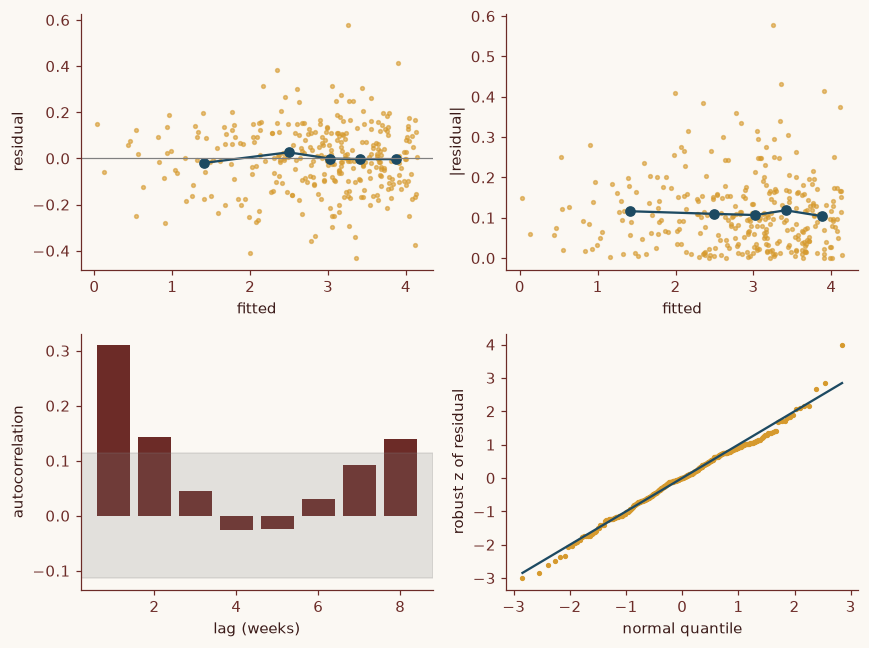

In [5]:
m1 = smf.ols("np.log(volume) ~ variety * (week + I(week**2)) + farm + C(season)", train).fit()
residual_report(m1.resid, m1.fittedvalues, [train.farm, train.variety, train.season])

<strong>Figure 2 | The right shape on the log scale.</strong> Panels as in Figure 1. Pattern and spread are gone; the lag-1 bar and one high Q–Q point remain.

The fifth means are within $0.03$ of zero and the spread ratio is $0.97$. The next cell measures the same curve's residuals in tonnes, using $e^{\hat{y}}$.

In [6]:
tonnes = np.exp(m1.fittedvalues)                    # the same fitted curve, in t/week
residual_report(train.volume - tonnes, tonnes, [train.farm, train.variety, train.season], plot=False)

mean residual by fitted fifth: [-0.08, 0.41, 0.22, 0.29, 0.17]
spread, top/bottom third of fitted: 4.99
lag-1 autocorrelation: 0.28; Ljung-Box (4 lags) p = 2e-10
excess kurtosis: 7.6; largest robust z: 11.6 at row 352


With exactly the same curve, the raw-scale spread ratio is $4.99$. That is what proportional errors look like: a 10% miss on a 60-tonne week is ten times one on a 6-tonne week. The raw residuals also average above zero in four of five fifths, because $e^{\hat{y}}$ is a median, not a mean (corrected below).

## Persistence and the odd week

Two findings remain in Figure 2: the lag-1 bar and the high Q–Q point. Take the point first; one bad value distorts every other statistic.

In [7]:
worst = m1.resid.abs().idxmax()
print(df.loc[worst, keys + ["week"]].to_dict(), f"residual {m1.resid[worst]:.2f} = {np.exp(m1.resid[worst]):.2f} x the fit")
print(f"typical largest |z| in {len(train)} normal draws: {stats.norm.ppf(0.5 + 0.5 * 0.5 ** (1 / len(train))):.1f}")
df.loc[typo, "volume"] /= 2                                  # in real life: check the weighbridge record
train = df[df.season < 3]
m1 = smf.ols("np.log(volume) ~ variety * (week + I(week**2)) + farm + C(season)", train).fit()
residual_report(m1.resid, m1.fittedvalues, [train.farm, train.variety, train.season], plot=False)

{'farm': 'B', 'variety': 'late', 'season': 2, 'week': 14} residual 0.58 = 1.78 x the fit
typical largest |z| in 312 normal draws: 3.1
mean residual by fitted fifth: [-0.02, 0.03, 0.01, -0.01, -0.0]
spread, top/bottom third of fitted: 0.97
lag-1 autocorrelation: 0.36; Ljung-Box (4 lags) p = 1e-10
excess kurtosis: 0.2; largest robust z: 3.1 at row 5


The flagged row is the load entered twice: a robust z of $4.0$, against $3.1$ for the typical largest of 312 normal draws. On real data, check the source; fix the record if it is wrong and keep it if it is real ([Heavy tails](../heavy-tails.qmd) explains why).

With the record fixed, the lag-1 autocorrelation is $0.36$ and Ljung–Box gives $p = 10^{-10}$. Read Ljung–Box as an action: a p-value below about $0.05$ means neighbouring residuals move together, so add a lag feature or widen the intervals.

::: {.callout-note collapse="true"}
## The Ljung–Box statistic

$$Q = n(n+2) \sum_{k=1}^{h} \frac{\hat{\rho}_k^2}{n-k}$$

where $\hat\rho_k$ is the lag-$k$ residual autocorrelation within a series, $n$ the number of residuals and $h$ the number of lags (4 here). Under independence $Q$ is roughly chi-squared with $h$ degrees of freedom, a better approximation than for the earlier Box–Pierce statistic[^2]. Pooling $\hat\rho_k$ across the twelve training series is my shortcut, not the textbook per-series test.
:::

::: {.callout-note collapse="true"}
## Where 0.36 comes from (checks the simulation; skip if you like)

The weather term has variance $0.12^2 = 0.0144$ and carries $0.6$ of itself into the next week; the shocks have variance $0.06^2 \times 3 = 0.0108$ (a t with 3 degrees of freedom has variance 3) and carry nothing. The lag-1 correlation of their sum is $0.6 \times 0.0144 / 0.0252 = 0.34$, close to the $0.36$ measured.
:::

For a forecaster, persistence means errors come in runs, so intervals built on independent errors are too narrow (standard errors too, as [Is the trend significant?](../trend-significance/is_the_trend_significant.ipynb) shows). A lag feature captures part of the run. The third model adds last week's log volume, known at the forecast origin, and drops the season offset, which a forecast cannot know.

In [8]:
df["last_week"] = np.log(df.groupby(keys).volume.shift(1))     # known at the forecast origin
train = df[df.season < 3].dropna()
m2 = smf.ols("np.log(volume) ~ variety * (week + I(week**2)) + farm + last_week", train).fit()
print(f"coefficient on last week's log volume: {m2.params['last_week']:.2f}")
z = m2.resid / m2.resid.std()
print(f"beyond 2.58 SD: {(z.abs() > 2.58).mean():.1%} of residuals (normal: 1%)")
residual_report(m2.resid, m2.fittedvalues, [train.farm, train.variety, train.season], plot=False)

coefficient on last week's log volume: 0.42
beyond 2.58 SD: 2.3% of residuals (normal: 1%)
mean residual by fitted fifth: [-0.01, 0.01, 0.01, -0.0, -0.01]
spread, top/bottom third of fitted: 1.10
lag-1 autocorrelation: -0.05; Ljung-Box (4 lags) p = 0.4
excess kurtosis: 1.1; largest robust z: 3.6 at row 5


Last week's log volume gets a coefficient of $0.42$; lag-1 autocorrelation falls to $-0.05$ and Ljung–Box gives $p = 0.4$. Treat that as roughly fine, not proof: Box and Pierce showed that ignoring a model's fitted terms when testing residual autocorrelations tends to overlook lack of fit[^3], and by my inference a lagged target is such a term.

With persistence removed, the heavy-tailed one-off weeks show: excess kurtosis is $1.1$, and $2.3\%$ of residuals lie beyond $2.58$ standard deviations, where a normal puts $1\%$. Normal-theory intervals undercover; take them from the residuals' own quantiles, or use [conformal prediction](../conformal-prediction/conformal_prediction.ipynb). To report in tonnes, exponentiate the log forecast for a median and the log-scale bounds for the interval:

In [9]:
lo, hi = np.quantile(m2.resid, [0.1, 0.9])                  # 80% band on the log scale
log_fc = m2.predict(df[df.season == 3].dropna())
median_t, lo_t, hi_t = np.exp(log_fc), np.exp(log_fc + lo), np.exp(log_fc + hi)   # t/week

Quantiles survive the exponential, so the band keeps its 80%. The mean does not; a weekly total needs the correction in [Log and Box–Cox transforms](../log-and-boxcox-transforms.qmd).

## Residuals by group and over time

The third model, fitted on seasons 1 and 2, now forecasts season 3 one week ahead. Two cuts find most production problems: the mean by group and the running total by week.

In [10]:
test = df[df.season == 3].dropna().copy()
test["resid"] = np.log(test.volume) - m2.predict(test)        # log actual - log forecast
by_group = test.groupby(["farm", "variety"]).resid.agg(["mean", "sem"])
by_group["bias_%"] = 100 * (np.exp(by_group["mean"]) - 1)
print(by_group.round(3))
before, after = [test[(test.farm == "C") & cond].resid.mean() for cond in (test.week < 12, test.week >= 12)]
print(f"farm C mean residual: weeks 2-11 {before:.3f}, weeks 12-26 {after:.3f}")

               mean    sem  bias_%
farm variety                      
A    early    0.014  0.030   1.430
     late     0.002  0.029   0.241
B    early   -0.047  0.022  -4.587
     late     0.022  0.035   2.198
C    early    0.126  0.039  13.463
     late     0.101  0.030  10.589
farm C mean residual: weeks 2-11 0.021, weeks 12-26 0.175


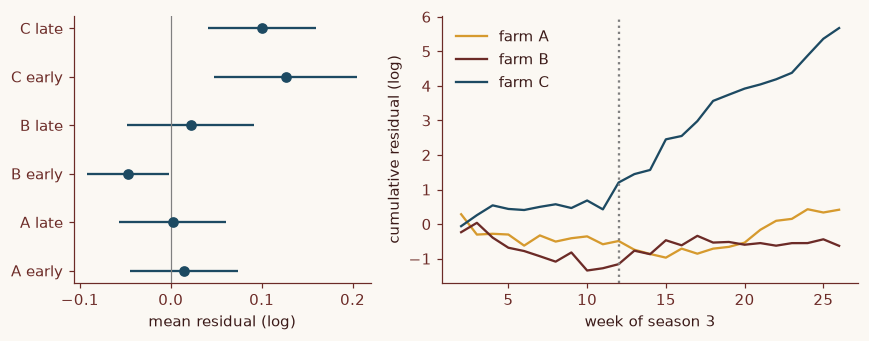

In [11]:
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})
a.errorbar(by_group["mean"], [f"{f} {v}" for f, v in by_group.index], xerr=2 * by_group["sem"], fmt="o", color=c1)
a.axvline(0, color="grey", lw=0.8)
a.set(xlabel="mean residual (log)")
for f, col in zip("ABC", (c2, c3, c1)):
    cum = test[test.farm == f].groupby("week").resid.sum().cumsum()
    b.plot(cum.index, cum, color=col, label=f"farm {f}")
b.axvline(12, color="grey", ls=":")
b.set(xlabel="week of season 3", ylabel="cumulative residual (log)"), b.legend(frameon=False)
fig.tight_layout()
plt.show()

<strong>Figure 3 | One farm changed.</strong> Left: mean log residual in season 3 by farm and variety, $\pm 2$ standard errors. Right: running sum of residuals by farm (both varieties); dotted line, week 12, when farm C's new block starts.

Farm C is under-forecast by $13.5\%$ (early) and $10.6\%$ (late). Its mean residual is $0.021$ in weeks 2 to 11 and $0.175$ in weeks 12 to 26, an under-forecast of $e^{0.175} - 1 = 19\%$, less than the true 30% step because the lag feature absorbs part of it. My arithmetic: actuals rise by $\ln 1.3 = 0.262$, the forecast follows through the $0.42$ coefficient, so the persisting gap is $(1 - 0.42) \times 0.262 = 0.152$, a $16\%$ under-forecast, close to what the residuals show.

Farm B's early variety sits just outside zero too, $-0.047$ against $2 \times 0.022 = 0.044$, but with six groups the chance that at least one misses by luck is $1 - 0.95^6 = 26\%$. One marginal group is not evidence; a sustained run in the running sum is.

The fix is a variable, not a transform: bearing area by block would let the model scale farm C. Until then the running sum is the alarm; [Monitoring a forecast](../monitoring/monitoring_a_forecast.ipynb) turns it into a CUSUM and sets the limit by injecting a ramp into your own backtest errors.

## Key takeaways

- A misfit in the mean leaks into every other check. Fix the shape before reading the rest.
- Compare the spread of one fitted curve on the raw and log scales; flat only on the log means proportional errors.
- A lag feature clears residual autocorrelation but absorbs only part of a level shift.
- Each week, update the mean residual by group and the running sum by farm; act on a sustained run, not one marginal group.

## References

[^1]: Anscombe, F. J. & Tukey, J. W. The examination and analysis of residuals. *Technometrics* **5**, 141–160 (1963). https://doi.org/10.1080/00401706.1963.10490071
[^2]: Ljung, G. M. & Box, G. E. P. On a measure of lack of fit in time series models. *Biometrika* **65**, 297–303 (1978). https://doi.org/10.1093/biomet/65.2.297
[^3]: Box, G. E. P. & Pierce, D. A. Distribution of residual autocorrelations in autoregressive-integrated moving average time series models. *J. Am. Stat. Assoc.* **65**, 1509–1526 (1970). https://doi.org/10.1080/01621459.1970.10481180

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/trend-significance/is_the_trend_significant.html"><span>Previous</span>Is the trend significant?</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/confidence-intervals.html"><span>Next</span>Confidence intervals</a></div>
<!-- CURRICULUM_FOOTER_END -->